# Credit Card Fraud Detection — Improved Machine Learning Workflow

**Project:** 3MTT Capstone  
**Dataset:** European card transactions (September 2013)  
**Objective:** Identify fraudulent transactions (`Class = 1`) while evaluating the precision–recall trade-off under severe class imbalance.

This notebook improves the original workflow by:
- checking and documenting missing values and duplicate records;
- splitting data before fitting preprocessing steps;
- fitting scaling and resampling only within the training pipeline;
- comparing Logistic Regression with SMOTE against a class-weighted Random Forest;
- selecting a decision threshold using validation data, then evaluating once on a held-out test set;
- reporting precision, recall, F1, F2, average precision (PR-AUC), ROC-AUC and confusion matrices;
- saving the fitted model and its selected threshold for reproducible inference.

**Important evaluation note:** this notebook uses stratified random splits. It estimates performance on a held-out sample from the same dataset, not necessarily performance on future transactions. A chronological evaluation is a useful additional experiment because `Time` records transaction time over a short period.

## 1. Setup and imports

If you are using Google Colab, upload `creditcard.csv` to the session or mount Google Drive, then set `DATA_PATH` to the file location. Do not commit the dataset to GitHub.

In [1]:
# Uncomment this line in a fresh Colab runtime if needed:
# !pip -q install imbalanced-learn

import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline as SklearnPipeline
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    average_precision_score, roc_auc_score, precision_recall_curve,
    confusion_matrix, classification_report, precision_score,
    recall_score, f1_score, fbeta_score
)

RANDOM_STATE = 42
DATA_PATH = "/mnt/data/fraud_analysis/creditcard.csv"  # Change this if your file is elsewhere

## 2. Load and inspect the dataset

In [2]:
if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"Could not find {DATA_PATH}. Upload creditcard.csv and update DATA_PATH."
    )

df = pd.read_csv(DATA_PATH)
print("Dataset shape:", df.shape)
display(df.head())
display(df.dtypes.value_counts())
display(df.isna().sum().sort_values(ascending=False).head())

Dataset shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


float64    30
int64       1
Name: count, dtype: int64

Time    0
V1      0
V2      0
V3      0
V4      0
dtype: int64

## 3. Data quality and class imbalance

In [3]:
if "Class" not in df.columns:
    raise ValueError("Expected target column 'Class' was not found.")

print("Missing values:", int(df.isna().sum().sum()))
print("\nClass counts:")
display(df["Class"].value_counts().sort_index().rename(index={0: "Legitimate (0)", 1: "Fraud (1)"}))

fraud_rate = 100 * df["Class"].mean()
print(f"Fraud share: {fraud_rate:.4f}%")

duplicate_count = int(df.duplicated().sum())
print("Exact duplicate rows:", duplicate_count)

# Remove exact duplicate rows before splitting so identical records cannot
# appear in both training and evaluation partitions.
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing exact duplicates:", df.shape)
print("Class counts after duplicate removal:")
display(df["Class"].value_counts().sort_index())

Missing values: 0

Class counts:


Class
Legitimate (0)    284315
Fraud (1)            492
Name: count, dtype: int64

Fraud share: 0.1727%


Exact duplicate rows: 1081


Shape after removing exact duplicates: (283726, 31)
Class counts after duplicate removal:


Class
0    283253
1       473
Name: count, dtype: int64

**Why duplicates are handled before splitting:** identical rows in both training and test partitions can make evaluation overly optimistic. This step removes exact duplicates only; it does not remove merely similar transactions. The original dataset contains repeated rows, so the number removed is reported above.

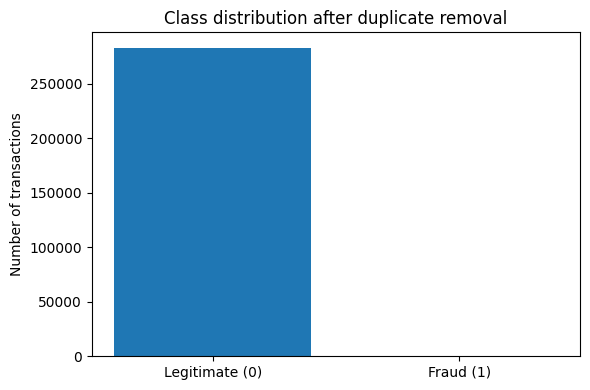

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,283253.0,88.41,250.38,0.0,5.67,22.00,77.46,25691.16
1,473.0,123.87,260.21,0.0,1.00,9.82,105.89,2125.87


In [4]:
# Basic visualisation of the target imbalance
class_counts = df["Class"].value_counts().sort_index()
plt.figure(figsize=(6, 4))
plt.bar(["Legitimate (0)", "Fraud (1)"], class_counts.values)
plt.title("Class distribution after duplicate removal")
plt.ylabel("Number of transactions")
plt.tight_layout()
plt.show()

display(df.groupby("Class")["Amount"].describe().round(2))

## 4. Define features and create train, validation and test sets

In [5]:
X = df.drop(columns=["Class"])
y = df["Class"].astype(int)

# 60% train, 20% validation, 20% test; stratification preserves the rare class.
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, random_state=RANDOM_STATE, stratify=y
)
X_valid, X_test, y_valid, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE, stratify=y_temp
)

print("Train:", X_train.shape, "Fraud:", int(y_train.sum()))
print("Validation:", X_valid.shape, "Fraud:", int(y_valid.sum()))
print("Test:", X_test.shape, "Fraud:", int(y_test.sum()))

Train: (170235, 30) Fraud: 284
Validation: (56745, 30) Fraud: 94
Test: (56746, 30) Fraud: 95


## 5. Build leakage-safe preprocessing and model pipelines

`V1`–`V28` are anonymised PCA-derived features in this dataset. `Time` and `Amount` are scaled. The scaler is fitted only on the training partition because it is inside each pipeline.

- **Model A:** Logistic Regression with SMOTE. SMOTE is applied only when the pipeline is fitted on training data.
- **Model B:** Random Forest with balanced class weights. It uses the original training distribution and does not need SMOTE.

The validation and test data are never resampled.

In [6]:
scale_columns = ["Time", "Amount"]
preprocessor = ColumnTransformer(
    transformers=[
        ("scale_time_amount", StandardScaler(), scale_columns)
    ],
    remainder="passthrough"
)

logistic_smote = ImbPipeline(steps=[
    ("preprocess", preprocessor),
    ("smote", SMOTE(random_state=RANDOM_STATE, sampling_strategy="auto")),
    ("model", LogisticRegression(
        max_iter=3000,
        solver="lbfgs",
        random_state=RANDOM_STATE
    ))
])

random_forest = SklearnPipeline(steps=[
    ("preprocess", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200,
        max_depth=18,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=RANDOM_STATE
    ))
])

models = {
    "Logistic Regression + SMOTE": logistic_smote,
    "Random Forest (class-weighted)": random_forest
}

## 6. Train and compare models on the validation set

In [7]:
validation_results = []
fitted_models = {}

for name, model in models.items():
    print(f"Training: {name}")
    model.fit(X_train, y_train)
    fitted_models[name] = model

    valid_scores = model.predict_proba(X_valid)[:, 1]
    validation_results.append({
        "Model": name,
        "Average Precision (PR-AUC)": average_precision_score(y_valid, valid_scores),
        "ROC-AUC": roc_auc_score(y_valid, valid_scores),
        "Precision at 0.50": precision_score(y_valid, valid_scores >= 0.50, zero_division=0),
        "Recall at 0.50": recall_score(y_valid, valid_scores >= 0.50, zero_division=0),
        "F1 at 0.50": f1_score(y_valid, valid_scores >= 0.50, zero_division=0)
    })

validation_table = pd.DataFrame(validation_results).sort_values(
    "Average Precision (PR-AUC)", ascending=False
)
display(validation_table)

Training: Logistic Regression + SMOTE


Training: Random Forest (class-weighted)


,Model,Average Precision (PR-AUC),ROC-AUC,Precision at 0.50,Recall at 0.50,F1 at 0.50
1,Random Forest (class-weighted),0.796331,0.952453,0.932432,0.734043,0.821429
0,Logistic Regression + SMOTE,0.690880,0.972151,0.055749,0.851064,0.104644


**Model selection:** choose the model with the higher validation Average Precision. Average Precision summarises the precision–recall curve and is particularly informative when the positive class is very rare. The test set remains untouched during model selection.

In [8]:
best_model_name = validation_table.iloc[0]["Model"]
best_model = fitted_models[best_model_name]
valid_scores = best_model.predict_proba(X_valid)[:, 1]

print("Selected model:", best_model_name)

Selected model: Random Forest (class-weighted)


## 7. Select a decision threshold using validation data

Selected validation threshold (max F2): 0.193788
Validation precision: 0.8242
Validation recall: 0.7979
Validation F2: 0.8030


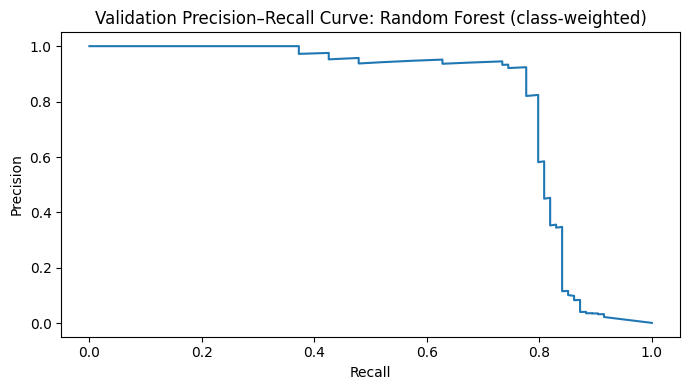

In [9]:
precision_values, recall_values, thresholds = precision_recall_curve(y_valid, valid_scores)

# F2 gives recall more weight than precision. This is a modelling choice,
# not a universal business rule; the threshold should ultimately reflect
# the operational cost of missed fraud versus false alerts.
beta = 2
f2_values = (
    (1 + beta**2) * precision_values[:-1] * recall_values[:-1]
    / (beta**2 * precision_values[:-1] + recall_values[:-1] + 1e-12)
)
best_idx = int(np.nanargmax(f2_values))
selected_threshold = float(thresholds[best_idx])

print(f"Selected validation threshold (max F2): {selected_threshold:.6f}")
print(f"Validation precision: {precision_values[best_idx]:.4f}")
print(f"Validation recall: {recall_values[best_idx]:.4f}")
print(f"Validation F2: {f2_values[best_idx]:.4f}")

plt.figure(figsize=(7, 4))
plt.plot(recall_values, precision_values)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title(f"Validation Precision–Recall Curve: {best_model_name}")
plt.tight_layout()
plt.show()

## 8. Final evaluation on the untouched test set

The selected model and threshold are now applied to the test set. Do not change the threshold after inspecting test results; if further tuning is needed, return to the training/validation process.

In [10]:
test_scores = best_model.predict_proba(X_test)[:, 1]
test_pred_050 = (test_scores >= 0.50).astype(int)
test_pred_tuned = (test_scores >= selected_threshold).astype(int)

def evaluate_predictions(y_true, scores, predictions, label):
    print(f"\n--- {label} ---")
    print("Average Precision (PR-AUC):", round(average_precision_score(y_true, scores), 4))
    print("ROC-AUC:", round(roc_auc_score(y_true, scores), 4))
    print("Precision:", round(precision_score(y_true, predictions, zero_division=0), 4))
    print("Recall:", round(recall_score(y_true, predictions, zero_division=0), 4))
    print("F1:", round(f1_score(y_true, predictions, zero_division=0), 4))
    print("F2:", round(fbeta_score(y_true, predictions, beta=2, zero_division=0), 4))
    print("\nConfusion matrix [ [TN, FP], [FN, TP] ]:")
    print(confusion_matrix(y_true, predictions))
    print("\nClassification report:")
    print(classification_report(y_true, predictions, target_names=["Legitimate", "Fraud"], zero_division=0))

evaluate_predictions(y_test, test_scores, test_pred_050, "Test set — default threshold 0.50")
evaluate_predictions(y_test, test_scores, test_pred_tuned, f"Test set — validation-selected threshold {selected_threshold:.6f}")


--- Test set — default threshold 0.50 ---
Average Precision (PR-AUC): 0.8529
ROC-AUC: 0.9707
Precision: 0.9595
Recall: 0.7474
F1: 0.8402
F2: 0.7819

Confusion matrix [ [TN, FP], [FN, TP] ]:
[[56648     3]
 [   24    71]]

Classification report:
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56651
       Fraud       0.96      0.75      0.84        95

    accuracy                           1.00     56746
   macro avg       0.98      0.87      0.92     56746
weighted avg       1.00      1.00      1.00     56746


--- Test set — validation-selected threshold 0.193788 ---
Average Precision (PR-AUC): 0.8529
ROC-AUC: 0.9707
Precision: 0.8864
Recall: 0.8211
F1: 0.8525
F2: 0.8333

Confusion matrix [ [TN, FP], [FN, TP] ]:
[[56641    10]
 [   17    78]]

Classification report:
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56651
       Fraud       0.89      0.82      0.85        95

 

## 9. Inspect false positives and false negatives

In [11]:
test_review = X_test.copy()
test_review["Actual_Class"] = y_test
test_review["Fraud_Probability"] = test_scores
test_review["Predicted_Class_Tuned"] = test_pred_tuned

false_positives = test_review[
    (test_review["Actual_Class"] == 0) & (test_review["Predicted_Class_Tuned"] == 1)
]
false_negatives = test_review[
    (test_review["Actual_Class"] == 1) & (test_review["Predicted_Class_Tuned"] == 0)
]

print("False positives:", len(false_positives))
print("False negatives:", len(false_negatives))
display(false_positives.head())
display(false_negatives.head())

False positives: 10
False negatives: 17


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Actual_Class,Fraud_Probability,Predicted_Class_Tuned
10639,18064.0,-3.408448,4.634203,-8.986378,5.767694,-4.340056,-3.267062,-8.215842,2.652823,-3.323071,-11.028734,9.659773,-14.919028,0.003169,-13.377658,-0.479967,-9.981433,-16.668179,-5.133154,2.042806,1.348395,1.499485,-0.277509,0.013462,-0.020885,-0.057518,-0.303920,2.096459,0.670476,89.99,0,0.369609,1
276728,167846.0,-6.595915,3.303062,-5.993793,1.149137,-3.747111,-1.744032,-4.605288,2.507996,-1.427849,-3.074267,1.534129,-2.641025,-1.352493,-0.758264,-0.185784,-2.618810,-5.535266,-1.283769,1.135119,-1.588040,2.005201,1.003597,0.529591,0.045122,-0.618878,-0.334612,-1.759107,0.357327,1.99,0,0.254540,1
114447,73667.0,-3.423854,1.579438,-1.338452,1.012327,-1.363651,-1.063367,-1.643178,0.783429,-0.356442,-1.562108,1.298497,-3.452937,-1.283095,-3.099716,1.410005,-2.371151,-4.339989,-2.230347,0.149618,0.073917,0.002688,-0.683665,0.209910,-0.031626,-0.071505,0.048280,-0.225216,-0.189759,8.99,0,0.504807,1
172172,121251.0,-0.461571,3.140351,-2.752211,3.580295,3.243804,-1.462513,1.979739,-0.040094,-2.635506,-2.276613,2.163028,-3.012751,-3.135022,-6.754423,-0.614560,3.414608,5.229776,3.864315,-2.423356,-0.099698,-0.248399,-0.903682,-0.468425,-1.168654,0.091457,0.057969,0.142405,0.300641,10.61,0,0.219845,1
189359,128663.0,-1.563664,2.299232,-3.601661,1.461297,0.493803,-1.607444,-1.524454,0.816681,-2.633927,-4.407026,3.516813,-3.441694,-0.257784,-5.542357,-0.514741,-3.226827,-3.532616,-0.952772,1.664605,0.550943,0.662774,0.366741,-0.430649,0.519112,0.251580,0.848723,0.545892,0.324340,0.76,0,0.919873,1


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Actual_Class,Fraud_Probability,Predicted_Class_Tuned
72475,54846.0,-2.986466,-0.000891,0.605887,0.338338,0.685448,-1.581954,0.504206,-0.233403,0.636768,1.010291,0.004518,0.044397,0.420853,-0.931614,1.147974,0.483063,-0.152471,-0.285666,0.072550,-0.764274,-0.875146,-0.509849,1.313918,0.355065,0.448552,0.193490,1.214588,-0.013923,1.79,1,0.000000,0
52289,45501.0,1.001992,0.047938,-0.349002,1.493958,0.186939,0.190966,-0.001112,0.147140,0.580415,-0.792938,-0.984172,-0.567380,-1.105592,-1.381214,0.405490,0.279890,1.132160,0.092993,-0.298920,0.016004,-0.334417,-1.014315,-0.128427,-0.946242,0.456090,-0.453206,0.046627,0.064698,105.99,1,0.004992,0
8933,12393.0,-4.064005,3.100935,-1.188498,3.264633,-1.903562,0.320351,-0.954940,-3.277535,2.820829,1.015113,3.187187,-7.004327,0.872711,-6.220605,-0.904445,-3.075092,-5.044736,-1.718083,-0.662462,-0.531898,1.688665,-0.078845,0.193731,0.479496,-0.506603,-0.409863,-3.036271,-0.630605,179.66,1,0.184832,0
10442,17187.0,1.088375,0.898474,0.394684,3.170258,0.175739,-0.221981,-0.022989,-0.010874,0.860044,-0.592473,1.072728,-2.547557,1.235950,-0.330306,-1.022354,0.335642,2.298998,-0.162096,-1.532707,-0.217358,-0.423554,-0.800852,0.077614,0.167608,0.350182,-0.118941,0.012948,0.054254,3.79,1,0.104736,0
248322,154309.0,-0.082983,-3.935919,-2.616709,0.163310,-1.400952,-0.809419,1.501580,-0.471000,1.519743,-1.134454,0.713878,0.979675,-1.339031,0.984993,-0.382471,-0.934616,-0.052419,0.511162,0.731999,1.878612,0.702672,-0.182305,-0.921017,0.111635,-0.071622,-1.125881,-0.170947,0.126221,1096.99,1,0.000000,0


## 10. Save the selected model and threshold

The threshold is saved alongside the model because using the default 0.50 threshold later would not reproduce the validation-selected decision rule.

In [12]:
artifact = {
    "model": best_model,
    "model_name": best_model_name,
    "threshold": selected_threshold,
    "feature_columns": X.columns.tolist()
}
MODEL_PATH = "credit_card_fraud_model.joblib"
joblib.dump(artifact, MODEL_PATH)
print("Saved:", MODEL_PATH)

Saved: /mnt/data/fraud_project/credit_card_fraud_model.joblib


## 11. Example inference on a new transaction

In [13]:
# Supply one row with the same feature columns used during training.
# Replace the example values with an actual transaction record.
# Do not include the target column 'Class'.

loaded_artifact = joblib.load(MODEL_PATH)
loaded_model = loaded_artifact["model"]
loaded_threshold = loaded_artifact["threshold"]
feature_columns = loaded_artifact["feature_columns"]

# Example: use a row from the test set only to demonstrate the prediction interface.
# For a real deployment, replace this with a new unseen transaction.
new_transaction = X_test.iloc[[0]][feature_columns].copy()

fraud_probability = float(loaded_model.predict_proba(new_transaction)[:, 1][0])
fraud_prediction = int(fraud_probability >= loaded_threshold)

print(f"Fraud probability: {fraud_probability:.6f}")
print("Predicted class:", fraud_prediction, "(1 = potential fraud, 0 = legitimate)")

Fraud probability: 0.000000
Predicted class: 0 (1 = potential fraud, 0 = legitimate)


## 12. Conclusions and limitations

1. The dataset is highly imbalanced, so accuracy alone is not a meaningful performance summary.
2. The preprocessing and resampling steps are contained inside the training pipelines to prevent information from validation/test partitions influencing fitted transformations or SMOTE.
3. The validation set is used for model selection and threshold selection; the test set is reserved for final evaluation.
4. Precision and recall represent a trade-off. A lower threshold may catch more fraud but can generate more false alerts. The appropriate operating point depends on the cost of each type of error.
5. The data contains anonymised PCA features and covers a limited time period. Results on this dataset do not establish performance on current real-world banking transactions.
6. A further experiment should evaluate a chronological split and, if possible, compare cost-sensitive learning and calibrated probabilities.

**Reproducibility:** record the package versions, random seed, selected model, threshold, and final test metrics when publishing the project.

## 13. Model analysis and explainability

This section analyses the selected model using the **validation set**, not the final test set. This keeps the test set reserved for the one-time performance estimate reported above. Permutation importance measures how much the model's Average Precision falls when one feature is shuffled. It is model-agnostic, but correlated features can share or mask importance.

The dataset's `V1`–`V28` columns are anonymised PCA components. Their importance can be ranked, but their original real-world meanings cannot be inferred from this dataset alone.


Permutation importance computed on a stratified validation sample of 10,000 records.


Feature  Mean AP decrease  Std. deviation
     V4          0.084781        0.015295
    V14          0.023661        0.018960
    V11          0.017915        0.007210
     V9          0.016212        0.032045
    V18          0.015895        0.004591
    V10          0.012701        0.009197
     V7          0.012242        0.009147
    V12          0.009366        0.018356
   Time          0.007684        0.003611
    V24          0.007047        0.002149
    V16          0.006774        0.012576
     V3          0.006686        0.019579
    V27          0.006482        0.002053
    V25          0.004312        0.002891
    V26          0.003523        0.004677


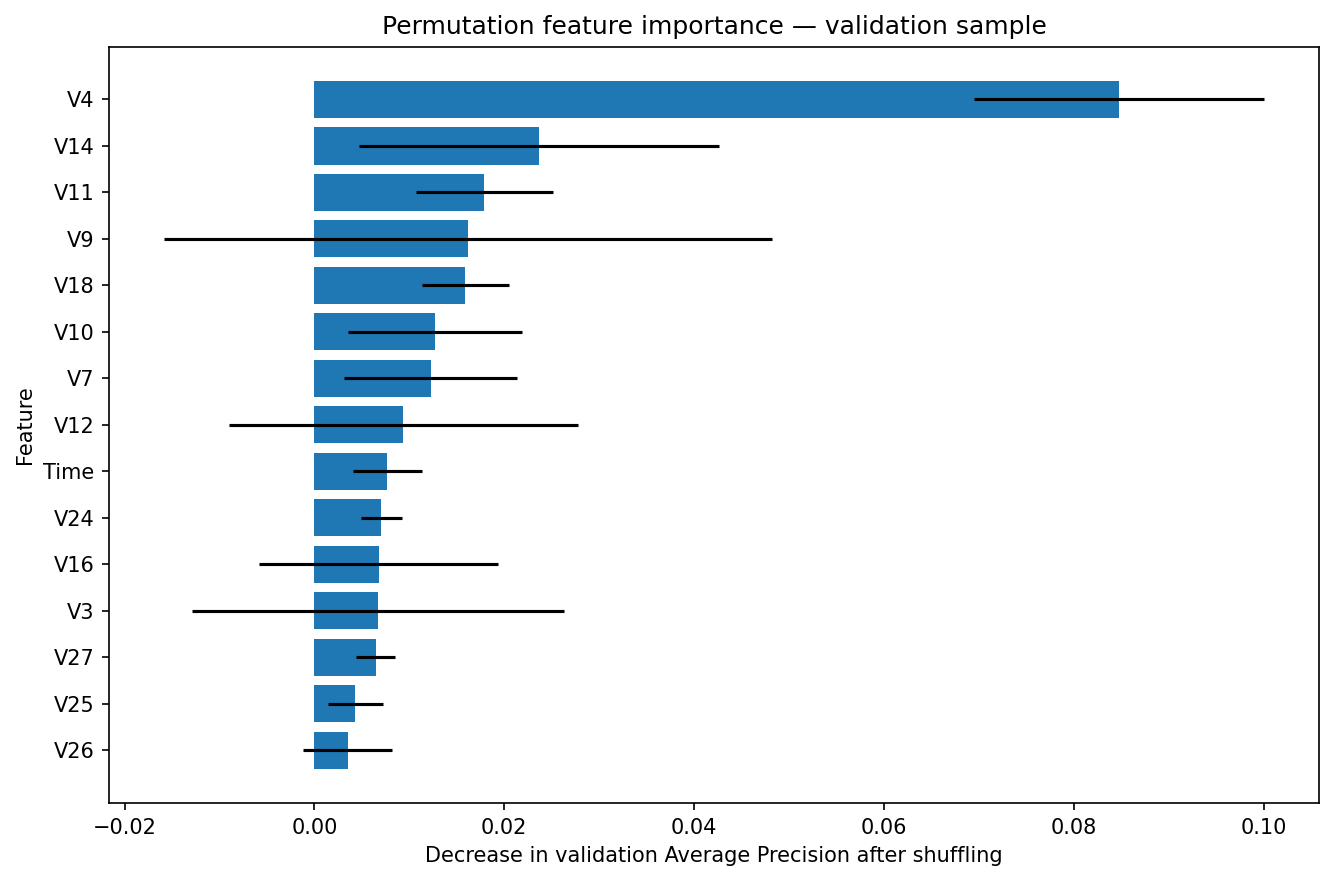

In [14]:
from sklearn.inspection import permutation_importance

# Use a reproducible stratified sample to keep permutation analysis practical.
analysis_n = min(10000, len(X_valid))
X_analysis = X_valid.sample(n=analysis_n, random_state=RANDOM_STATE)
y_analysis = y_valid.loc[X_analysis.index]

perm = permutation_importance(
    best_model,
    X_analysis,
    y_analysis,
    scoring="average_precision",
    n_repeats=3,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

permutation_table = pd.DataFrame({
    "Feature": X_analysis.columns,
    "Mean AP decrease": perm.importances_mean,
    "Std. deviation": perm.importances_std
}).sort_values("Mean AP decrease", ascending=False)

display(permutation_table.head(15).round(6))

plt.figure(figsize=(9, 6))
top_perm = permutation_table.head(15).sort_values("Mean AP decrease")
plt.barh(top_perm["Feature"], top_perm["Mean AP decrease"],
        xerr=top_perm["Std. deviation"])
plt.xlabel("Decrease in validation Average Precision after shuffling")
plt.ylabel("Feature")
plt.title("Permutation feature importance — validation sample")
plt.tight_layout()
plt.show()


### Interpreting permutation importance

- Larger positive values indicate that shuffling the feature harms validation ranking performance more.
- Values near zero suggest little measurable contribution under this model and sample.
- Negative values can occur from sampling variability or noise; they do not mean a feature is inherently harmful.
- Importance is predictive, not causal. It does not show that a feature causes fraud.


### Optional SHAP analysis

SHAP provides local explanations by estimating each feature's contribution to individual predictions. For this tree-based model, TreeExplainer can be used on the fitted Random Forest after applying the same preprocessing step. The code below is optional: install `shap` first if it is not already available. It uses a small sample to limit runtime.


SHAP TreeExplainer summary computed for 500 validation transactions. Values describe model contributions, not causal effects.


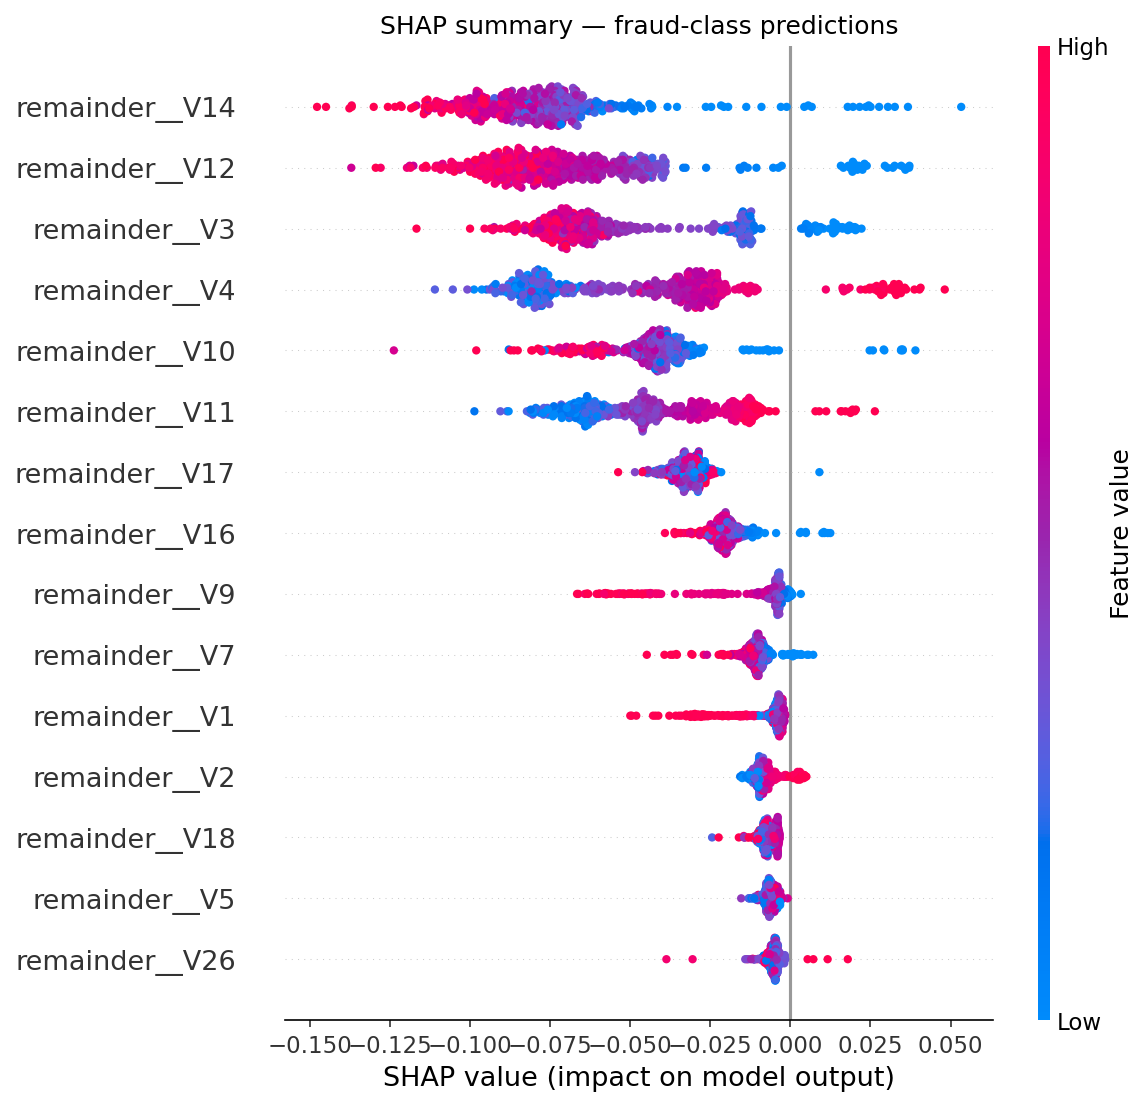

In [15]:
# Optional dependency: in a fresh Colab session, run this in a separate cell if needed:
# %pip -q install shap

try:
    import shap
    if hasattr(best_model, "named_steps") and "model" in best_model.named_steps:
        fitted_preprocessor = best_model.named_steps["preprocess"]
        fitted_estimator = best_model.named_steps["model"]
        shap_feature_names = fitted_preprocessor.get_feature_names_out()

        X_shap_raw = X_analysis.sample(n=min(500, len(X_analysis)), random_state=RANDOM_STATE)
        X_shap_transformed = fitted_preprocessor.transform(X_shap_raw)
        X_shap_frame = pd.DataFrame(X_shap_transformed,
                                    columns=shap_feature_names,
                                    index=X_shap_raw.index)

        explainer = shap.TreeExplainer(fitted_estimator)
        shap_values = explainer.shap_values(X_shap_frame)

        # For binary classifiers, SHAP versions may return a list by class or
        # a 3-D array. Select the fraud-class contributions robustly.
        if isinstance(shap_values, list):
            fraud_shap_values = shap_values[1]
        elif getattr(shap_values, "ndim", 0) == 3:
            fraud_shap_values = shap_values[:, :, 1]
        else:
            fraud_shap_values = shap_values

        shap.summary_plot(fraud_shap_values, X_shap_frame, show=False,
                          max_display=15)
        plt.title("SHAP summary — fraud-class predictions")
        plt.tight_layout()
        plt.show()
    else:
        print("SHAP TreeExplainer example is configured for the selected Random Forest pipeline.")
except ImportError:
    print("SHAP is not installed. To enable this optional analysis, run: %pip install shap")
except Exception as exc:
    print("Optional SHAP analysis could not be completed in this environment:", repr(exc))
    print("The executed permutation-importance analysis above remains available.")


### Model-analysis limitations

The feature rankings explain model behaviour on this validation sample; they are not evidence of causal drivers of fraud. Because `V1`–`V28` are transformed and anonymised, domain interpretation requires the original feature definitions, which are not provided with this dataset. SHAP results, when available, explain predictions from this fitted model and should not be treated as a substitute for domain review or external validation.
